# 04 - Differential diffraction pattern of the hBN b-centre versus defocus

The leading Jacobian modes at focus are a translation dipole pair, which suggests a
probe should be large enough to take in the whole excitation. This notebook tests that
directly: sweep the defocus, which spreads the probe in real space, and watch what
happens to the differential diffraction pattern.

For each defocus the figure shows

* **top row** - the excitation (differential phase) as the image, the base object phase
  as contours over it, and a yellow-green circle marking the measured probe size;
* **bottom row** - the differential diffraction pattern $\Delta I = I_{\text{excited}} -
  I_{\text{base}}$ on the camera, scaled as a percentage of the peak base intensity, with
  the total signal change annotated.

$\Delta I$ here is the **exact** difference of two forward models, not the linearized
$A_R h$ - no first-order approximation is involved. The single-slice forward model
$|\mathrm{crop}\,\mathcal{F}\{P O\}|^2$ reproduces abTEM's multislice intensity to a
relative $2\times10^{-6}$ on this object, so it is used directly.

The excitation is the Hamming-windowed phase difference throughout.

**A limit to respect:** the simulation cell is periodic. Once the probe's radius exceeds
half the cell it wraps onto itself and the diffraction pattern is an artefact. The sweep
reports the probe radius against the half-cell and flags any configuration that crosses it.

In [1]:
import sys
import pickle
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Circle

NOTEBOOK_DIR = Path.cwd()
if str(NOTEBOOK_DIR) not in sys.path:
    sys.path.insert(0, str(NOTEBOOK_DIR))

import linearized_jacobian as lj

print("notebook dir :", NOTEBOOK_DIR)
print("module       :", lj.__file__)

notebook dir : /home/rotem/ptycho_light/quantem/scripts/linearized-ptycho
module       : /home/rotem/ptycho_light/quantem/scripts/linearized-ptycho/linearized_jacobian.py


## Configuration

In [2]:
PHASE_CACHE_PATH = NOTEBOOK_DIR.parent / "bcenters_base_excited_phases_wide_fov.pkl"
PHASE_CACHE_KEY_BASE = "base"
PHASE_CACHE_KEY_EXCITED = "excited"

ACC_VOLTAGE_EV = 60e3
SLICE_THICKNESS_ANG = 1.0
PROBE_SEMIANGLE_MRAD = 30.0
DEFOCUS_SWEEP_ANG = [0.0, 25.0, 50.0, 100.0, 200.0, 400.0]
# Where to sit the probe. "dipole_midpoint" puts it between the two lobes of the
# excitation; the lobe positions are measured from the windowed phase, not hard-coded.
PROBE_POSITION_MODE = "dipole_midpoint"   # dipole_midpoint | negative_lobe | positive_lobe
                                          # | fov_centre | manual
PROBE_POSITION_MANUAL_OBJECT_ANG = (0.0, 0.0)
COMPARE_PROBE_POSITIONS = ["fov_centre", "negative_lobe", "dipole_midpoint", "positive_lobe"]

APPLY_HAMMING_TO_EXCITATION = True      # the user's convention for this notebook

PROBE_CIRCLE_ENCLOSED_FRACTIONS = (0.50, 0.90)   # drawn dashed and solid
PROBE_CIRCLE_COLOR = "#aacc00"
BASE_PHASE_CONTOUR_PERCENTILES = (92.0,)          # one level per atom; more drowns the image
BRIGHT_FIELD_CONTOUR_FRACTION = 0.01             # of peak base intensity, on the camera
DETECTOR_VIEW_HALFWIDTH_MRAD = 1.8 * 30.0        # crop the camera panels to +/- this
INTENSITY_FLOOR_FRACTION = 1e-4                  # for the Poisson detectability column

print("semiangle [mrad]  :", PROBE_SEMIANGLE_MRAD)
print("defocus sweep [A] :", DEFOCUS_SWEEP_ANG)
print("hamming window    :", APPLY_HAMMING_TO_EXCITATION)
print("probe position    :", PROBE_POSITION_MODE)

semiangle [mrad]  : 30.0
defocus sweep [A] : [0.0, 25.0, 50.0, 100.0, 200.0, 400.0]
hamming window    : True
probe position    : dipole_midpoint


## Load the object and the excitation

In [3]:
with open(PHASE_CACHE_PATH, "rb") as handle:
    phase_cache = pickle.load(handle)

phase_base = np.asarray(phase_cache[PHASE_CACHE_KEY_BASE], dtype=np.float32)
phase_excited_raw = np.asarray(phase_cache[PHASE_CACHE_KEY_EXCITED], dtype=np.float32)
object_x_ang = np.asarray(phase_cache["x"], dtype=np.float32)
object_y_ang = np.asarray(phase_cache["y"], dtype=np.float32)
object_sampling_ang = (
    float(object_y_ang[1] - object_y_ang[0]),
    float(object_x_ang[1] - object_x_ang[0]),
)

excitation_phase_rad = (phase_excited_raw - phase_base).astype(np.float32)
if APPLY_HAMMING_TO_EXCITATION:
    hamming_window = np.outer(
        np.hamming(excitation_phase_rad.shape[0]),
        np.hamming(excitation_phase_rad.shape[1]),
    ).astype(np.float32)
    excitation_phase_rad = (excitation_phase_rad * hamming_window).astype(np.float32)

# Both objects are built from the SAME excitation that is plotted and scored, so the
# differential diffraction pattern below is consistent with the top row by construction.
object_base = np.exp(1j * phase_base).astype(np.complex64)
object_excited = np.exp(1j * (phase_base + excitation_phase_rad)).astype(np.complex64)

potential = lj.make_phase_potential(
    phase_base, ACC_VOLTAGE_EV, SLICE_THICKNESS_ANG, object_sampling_ang
)
field_of_view_ang = tuple(float(v) for v in potential.extent)
half_cell_ang = field_of_view_ang[0] / 2
# Locate the two dipole lobes of the excitation from the windowed phase that is actually
# plotted and scored. Peak positions, not intensity-weighted centroids: the centroids are
# dragged towards each other by the broad tails and do not land where the eye sees lobes.
peak_row, peak_col = np.unravel_index(
    np.argmax(excitation_phase_rad), excitation_phase_rad.shape)
excitation_positive_lobe_ang = (float(object_x_ang[peak_col]), float(object_y_ang[peak_row]))
peak_row, peak_col = np.unravel_index(
    np.argmin(excitation_phase_rad), excitation_phase_rad.shape)
excitation_negative_lobe_ang = (float(object_x_ang[peak_col]), float(object_y_ang[peak_row]))
dipole_midpoint_ang = (
    0.5 * (excitation_positive_lobe_ang[0] + excitation_negative_lobe_ang[0]),
    0.5 * (excitation_positive_lobe_ang[1] + excitation_negative_lobe_ang[1]),
)
dipole_separation_ang = float(np.hypot(
    excitation_positive_lobe_ang[0] - excitation_negative_lobe_ang[0],
    excitation_positive_lobe_ang[1] - excitation_negative_lobe_ang[1],
))
field_of_view_centre_object_ang = (
    float(object_x_ang[0]) + field_of_view_ang[0] / 2,
    float(object_y_ang[0]) + field_of_view_ang[1] / 2,
)
PROBE_POSITION_OPTIONS_OBJECT_ANG = {
    "dipole_midpoint": dipole_midpoint_ang,
    "negative_lobe": excitation_negative_lobe_ang,
    "positive_lobe": excitation_positive_lobe_ang,
    "fov_centre": field_of_view_centre_object_ang,
    "manual": PROBE_POSITION_MANUAL_OBJECT_ANG,
}


def object_to_abtem_position_ang(position_object_ang):
    # abTEM measures from the array corner; the cached axes are centred on the defect.
    return (position_object_ang[0] - float(object_x_ang[0]),
            position_object_ang[1] - float(object_y_ang[0]))


probe_position_object_ang = PROBE_POSITION_OPTIONS_OBJECT_ANG[PROBE_POSITION_MODE]
probe_position_abtem_ang = object_to_abtem_position_ang(probe_position_object_ang)
object_extent_ang = [
    float(object_x_ang[0]), float(object_x_ang[-1]),
    float(object_y_ang[0]), float(object_y_ang[-1]),
]
reference_probe = lj.make_probe(ACC_VOLTAGE_EV, PROBE_SEMIANGLE_MRAD, 0.0, potential)
detector_shape = lj.valid_detector_shape(reference_probe)

# Camera axis in mrad: reciprocal sampling is 1/(n * dx), and angle = q * wavelength.
electron_wavelength_ang = float(reference_probe.wavelength)
detector_sampling_inv_ang = 1.0 / (phase_base.shape[0] * object_sampling_ang[0])
detector_pitch_mrad = detector_sampling_inv_ang * electron_wavelength_ang * 1e3
detector_halfwidth_mrad = (detector_shape[0] // 2) * detector_pitch_mrad
detector_extent_mrad = [-detector_halfwidth_mrad, detector_halfwidth_mrad,
                        -detector_halfwidth_mrad, detector_halfwidth_mrad]

# radius about the probe position, used for every enclosed-fraction radius below
row_index, col_index = np.mgrid[0:phase_base.shape[0], 0:phase_base.shape[1]]
radius_from_probe_ang = np.hypot(
    row_index - (probe_position_object_ang[1] - object_y_ang[0]) / object_sampling_ang[0],
    col_index - (probe_position_object_ang[0] - object_x_ang[0]) / object_sampling_ang[1],
) * object_sampling_ang[0]
radial_order = np.argsort(radius_from_probe_ang.ravel())
sorted_radius_ang = radius_from_probe_ang.ravel()[radial_order]


def enclosed_radius_ang(image_2d, fraction):
    cumulative = np.cumsum(image_2d.ravel()[radial_order])
    cumulative = cumulative / cumulative[-1]
    return float(sorted_radius_ang[np.searchsorted(cumulative, fraction)])


excitation_radii_ang = [
    enclosed_radius_ang(excitation_phase_rad ** 2, f)
    for f in PROBE_CIRCLE_ENCLOSED_FRACTIONS
]
print("object grid                 :", phase_base.shape)
print("field of view [A]           :", field_of_view_ang, " half-cell:", half_cell_ang)
print("excitation negative lobe [A]:", excitation_negative_lobe_ang)
print("excitation positive lobe [A]:", excitation_positive_lobe_ang)
print("dipole midpoint [A]         :", dipole_midpoint_ang,
      f" separation {dipole_separation_ang:.3f} A")
print(f"probe position ({PROBE_POSITION_MODE}) [A]:", probe_position_object_ang,
      "  offset from FOV centre:",
      tuple(round(a - b, 3) for a, b in zip(probe_position_object_ang,
                                            field_of_view_centre_object_ang)))
print("detector shape (valid)      :", detector_shape)
print("detector pitch [mrad/px]    :", detector_pitch_mrad)
print("detector half-width [mrad]  :", detector_halfwidth_mrad)
print("excitation max |dphi| [rad] :", float(np.abs(excitation_phase_rad).max()))
print("excitation radii [A] at "
      f"{PROBE_CIRCLE_ENCLOSED_FRACTIONS}: "
      + ", ".join(f"{r:.2f}" for r in excitation_radii_ang))

object grid                 : (251, 251)
field of view [A]           : (24.09592914581299, 24.09592914581299)  half-cell: 12.047964572906494
excitation negative lobe [A]: (-0.09600000083446503, 0.0)
excitation positive lobe [A]: (3.6480000019073486, 1.2480000257492065)
dipole midpoint [A]         : (1.7760000005364418, 0.6240000128746033)  separation 3.947 A
probe position (dipole_midpoint) [A]: (1.7760000005364418, 0.6240000128746033)   offset from FOV centre: (1.728, 0.576)
detector shape (valid)      : (119, 119)
detector pitch [mrad/px]    : 2.0194533481543893
detector half-width [mrad]  : 119.14774754110897
excitation max |dphi| [rad] : 0.02105947770178318
excitation radii [A] at (0.5, 0.9): 2.82, 4.86


## Sweep the defocus

In [4]:
sweep = []
for defocus_ang in DEFOCUS_SWEEP_ANG:
    probe = lj.make_probe(
        ACC_VOLTAGE_EV, PROBE_SEMIANGLE_MRAD, defocus_ang, potential
    )
    probe_realspace = np.asarray(
        probe.build(scan=list(probe_position_abtem_ang)).compute().array
    ).astype(np.complex64)
    probe_intensity = np.abs(probe_realspace) ** 2

    camera_wave_base = lj.camera_wave_from_exit_wave(
        (probe_realspace * object_base).astype(np.complex64), detector_shape
    )
    camera_wave_excited = lj.camera_wave_from_exit_wave(
        (probe_realspace * object_excited).astype(np.complex64), detector_shape
    )
    intensity_base = (np.abs(camera_wave_base) ** 2).astype(np.float64)
    intensity_excited = (np.abs(camera_wave_excited) ** 2).astype(np.float64)
    differential_intensity = intensity_excited - intensity_base

    detector_floor = INTENSITY_FLOOR_FRACTION * intensity_base.max()
    kept = intensity_base > detector_floor
    poisson_d2_per_electron = float(
        (differential_intensity[kept] ** 2 / intensity_base[kept]).sum()
    )

    sweep.append(dict(
        defocus_ang=defocus_ang,
        probe_intensity=probe_intensity,
        probe_radii_ang=[enclosed_radius_ang(probe_intensity, f)
                         for f in PROBE_CIRCLE_ENCLOSED_FRACTIONS],
        intensity_base=intensity_base,
        differential_intensity=differential_intensity,
        redistributed_percent=100.0 * np.abs(differential_intensity).sum()
                              / intensity_base.sum(),
        peak_change_percent=100.0 * np.abs(differential_intensity).max()
                            / intensity_base.max(),
        rms_change_percent=100.0 * np.linalg.norm(differential_intensity)
                           / np.linalg.norm(intensity_base),
        poisson_d2_per_electron=poisson_d2_per_electron,
        probe_wraps=enclosed_radius_ang(probe_intensity,
                                        PROBE_CIRCLE_ENCLOSED_FRACTIONS[-1]) > half_cell_ang,
    ))
    print(f"defocus {defocus_ang:6.0f} A  probe r50/r90 = "
          f"{sweep[-1]['probe_radii_ang'][0]:5.2f} / {sweep[-1]['probe_radii_ang'][1]:5.2f} A"
          f"   sum|dI| = {sweep[-1]['redistributed_percent']:.4f} %"
          + ("   PROBE WRAPS THE CELL" if sweep[-1]["probe_wraps"] else ""))

defocus      0 A  probe r50/r90 =  1.70 /  2.30 A   sum|dI| = 0.1897 %
defocus     25 A  probe r50/r90 =  1.70 /  2.65 A   sum|dI| = 0.1950 %
defocus     50 A  probe r50/r90 =  1.80 /  3.07 A   sum|dI| = 0.2088 %
defocus    100 A  probe r50/r90 =  2.39 /  4.20 A   sum|dI| = 0.2699 %
defocus    200 A  probe r50/r90 =  4.09 /  6.63 A   sum|dI| = 0.2851 %
defocus    400 A  probe r50/r90 =  8.14 / 11.52 A   sum|dI| = 0.1534 %


## The figure

Top row: the excitation as the image (red positive, blue negative), the base object
phase as grey contours, and the probe size as yellow-green circles - dashed for the
radius holding 50% of the probe intensity, solid for 90%.

Bottom row: the differential diffraction pattern as a percentage of the peak base
intensity, with the bright-field edge as a grey contour. Each panel is annotated with
the fraction of all detected electrons that the excitation moves, and with the peak
change relative to the peak signal.

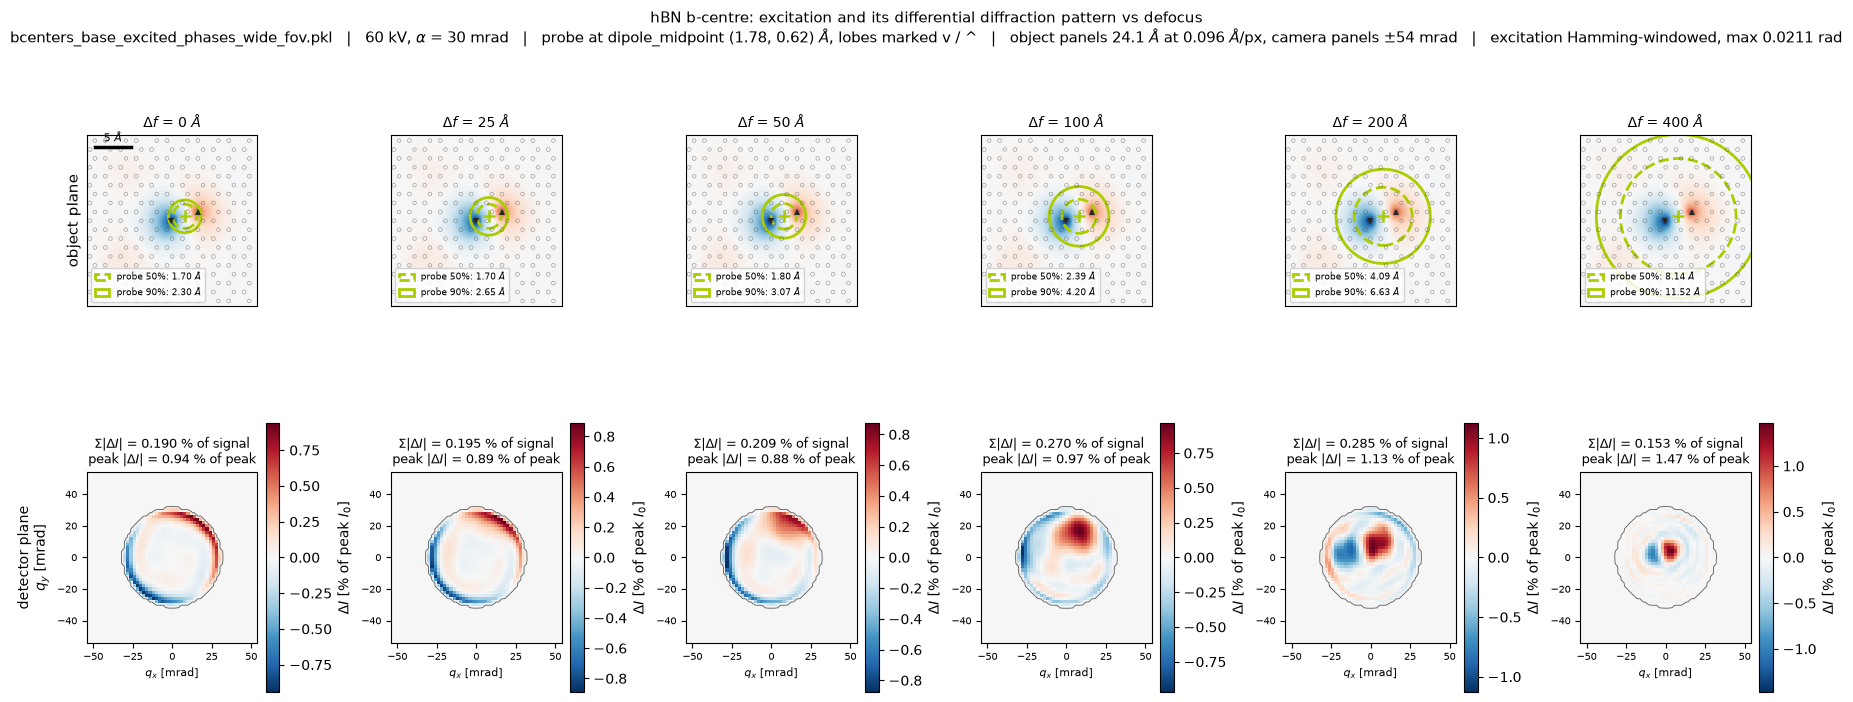

In [5]:
n_columns = len(sweep)
fig, axes = plt.subplots(
    2, n_columns, figsize=(3.05 * n_columns, 7.2), constrained_layout=True
)
base_phase_contour_levels = np.percentile(phase_base, BASE_PHASE_CONTOUR_PERCENTILES)
excitation_vmax = float(np.abs(excitation_phase_rad).max())

for column, entry in enumerate(sweep):
    # ---- top: object plane ----
    ax = axes[0, column]
    ax.imshow(
        excitation_phase_rad, extent=object_extent_ang, origin="lower",
        cmap="RdBu_r", vmin=-excitation_vmax, vmax=excitation_vmax,
        interpolation="nearest",
    )
    ax.contour(
        object_x_ang, object_y_ang, phase_base,
        levels=base_phase_contour_levels, colors="0.30", linewidths=0.45, alpha=0.55,
    )
    for radius_ang, fraction, style in zip(
        entry["probe_radii_ang"], PROBE_CIRCLE_ENCLOSED_FRACTIONS, ("--", "-")
    ):
        ax.add_patch(Circle(
            probe_position_object_ang, radius_ang, fill=False,
            edgecolor=PROBE_CIRCLE_COLOR, linewidth=2.0, linestyle=style,
            label=f"probe {fraction:.0%}: {radius_ang:.2f} $\\AA$",
        ))
    ax.plot(*excitation_negative_lobe_ang, marker="v", color="0.15", markersize=5,
            linestyle="none", markeredgewidth=0)
    ax.plot(*excitation_positive_lobe_ang, marker="^", color="0.15", markersize=5,
            linestyle="none", markeredgewidth=0)
    ax.plot(*probe_position_object_ang, marker="+", color=PROBE_CIRCLE_COLOR,
            markersize=9, markeredgewidth=1.8, linestyle="none")
    ax.set_xlim(object_extent_ang[:2])
    ax.set_ylim(object_extent_ang[2:])
    ax.set_xticks([])
    ax.set_yticks([])
    ax.legend(loc="lower left", fontsize=6.5, framealpha=0.85, handlelength=1.6)
    ax.set_title(
        f"$\\Delta f$ = {entry['defocus_ang']:.0f} $\\AA$"
        + ("\nPROBE WRAPS CELL" if entry["probe_wraps"] else ""),
        fontsize=10,
        color=("firebrick" if entry["probe_wraps"] else "black"),
    )

    # ---- bottom: detector plane ----
    ax = axes[1, column]
    differential_percent = (100.0 * entry["differential_intensity"]
                            / entry["intensity_base"].max())
    limit = float(np.abs(differential_percent).max())
    handle = ax.imshow(
        differential_percent, cmap="RdBu_r", vmin=-limit, vmax=limit,
        interpolation="nearest", extent=detector_extent_mrad, origin="lower",
    )
    detector_axis_mrad = (np.arange(detector_shape[0]) - detector_shape[0] // 2) * detector_pitch_mrad
    ax.contour(
        detector_axis_mrad, detector_axis_mrad, entry["intensity_base"],
        levels=[BRIGHT_FIELD_CONTOUR_FRACTION * entry["intensity_base"].max()],
        colors="0.35", linewidths=0.6,
    )
    ax.set_xlim(-DETECTOR_VIEW_HALFWIDTH_MRAD, DETECTOR_VIEW_HALFWIDTH_MRAD)
    ax.set_ylim(-DETECTOR_VIEW_HALFWIDTH_MRAD, DETECTOR_VIEW_HALFWIDTH_MRAD)
    ax.set_xlabel("$q_x$ [mrad]", fontsize=8)
    if column == 0:
        ax.set_ylabel("detector plane\n$q_y$ [mrad]", fontsize=10)
    ax.tick_params(labelsize=7)
    ax.set_title(
        f"$\\Sigma|\\Delta I|$ = {entry['redistributed_percent']:.3f} % of signal\n"
        f"peak $|\\Delta I|$ = {entry['peak_change_percent']:.2f} % of peak",
        fontsize=9,
    )
    fig.colorbar(handle, ax=ax, shrink=0.82, label="$\\Delta I$ [% of peak $I_0$]")

axes[0, 0].set_ylabel("object plane", fontsize=11)

# the object panels carry no axes, so they need a scale bar
scale_bar_ang = 5.0
scale_bar_ax = axes[0, 0]
scale_bar_ax.plot(
    [object_extent_ang[0] + 1.2, object_extent_ang[0] + 1.2 + scale_bar_ang],
    [object_extent_ang[3] - 1.6] * 2, color="black", linewidth=2.5,
)
scale_bar_ax.text(
    object_extent_ang[0] + 1.2 + scale_bar_ang / 2, object_extent_ang[3] - 1.3,
    f"{scale_bar_ang:.0f} $\\AA$", ha="center", va="bottom", fontsize=8,
)
fig.suptitle(
    f"hBN b-centre: excitation and its differential diffraction pattern vs defocus\n"
    f"{PHASE_CACHE_PATH.name}   |   {ACC_VOLTAGE_EV/1e3:.0f} kV, "
    f"$\\alpha$ = {PROBE_SEMIANGLE_MRAD:.0f} mrad   |   probe at {PROBE_POSITION_MODE} "
    f"({probe_position_object_ang[0]:.2f}, {probe_position_object_ang[1]:.2f}) $\\AA$, "
    f"lobes marked v / ^   |   "
    f"object panels {field_of_view_ang[0]:.1f} $\\AA$ at {object_sampling_ang[0]:.3f} "
    f"$\\AA$/px, camera panels $\\pm${DETECTOR_VIEW_HALFWIDTH_MRAD:.0f} mrad   |   "
    f"excitation Hamming-windowed, max {excitation_vmax:.4f} rad",
    fontsize=10.5,
)
plt.show()

## How the signal actually scales with probe size

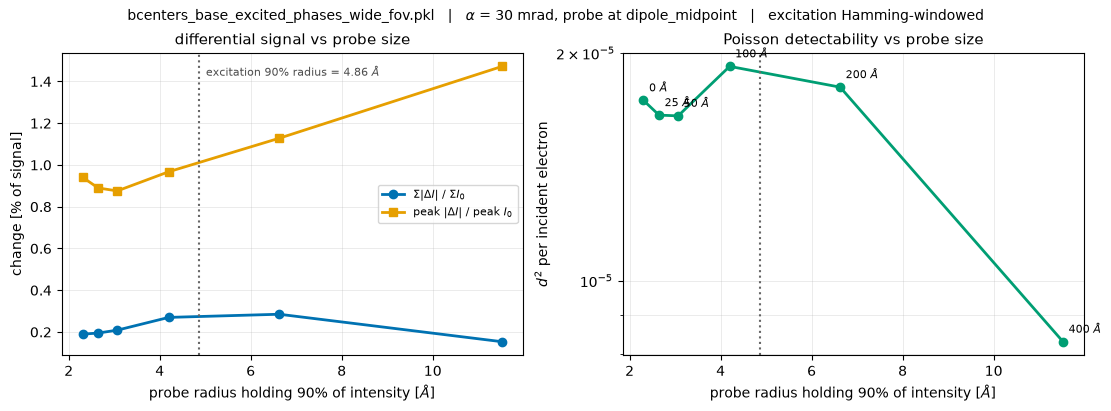

In [6]:
defocus_values = np.array([e["defocus_ang"] for e in sweep])
probe_radius90_ang = np.array([e["probe_radii_ang"][-1] for e in sweep])
redistributed = np.array([e["redistributed_percent"] for e in sweep])
peak_change = np.array([e["peak_change_percent"] for e in sweep])
detectability = np.array([e["poisson_d2_per_electron"] for e in sweep])

fig, axes = plt.subplots(1, 2, figsize=(11.0, 4.0), constrained_layout=True)

ax = axes[0]
ax.plot(probe_radius90_ang, redistributed, marker="o", color="#0072B2", linewidth=2.0,
        label="$\\Sigma|\\Delta I|$ / $\\Sigma I_0$")
ax.plot(probe_radius90_ang, peak_change, marker="s", color="#E69F00", linewidth=2.0,
        label="peak $|\\Delta I|$ / peak $I_0$")
ax.axvline(excitation_radii_ang[-1], color="0.4", linestyle=":", linewidth=1.5)
ax.text(excitation_radii_ang[-1], ax.get_ylim()[1] * 0.96,
        f"  excitation 90% radius = {excitation_radii_ang[-1]:.2f} $\\AA$",
        fontsize=8, va="top", color="0.3")
ax.set_xlabel("probe radius holding 90% of intensity [$\\AA$]")
ax.set_ylabel("change [% of signal]")
ax.set_title("differential signal vs probe size", fontsize=11)
ax.grid(True, alpha=0.25, linewidth=0.7)
ax.set_axisbelow(True)
ax.legend(fontsize=8)

ax = axes[1]
ax.plot(probe_radius90_ang, detectability, marker="o", color="#009E73", linewidth=2.0)
ax.axvline(excitation_radii_ang[-1], color="0.4", linestyle=":", linewidth=1.5)
ax.set_xlabel("probe radius holding 90% of intensity [$\\AA$]")
ax.set_ylabel("$d^2$ per incident electron")
ax.set_title("Poisson detectability vs probe size", fontsize=11)
ax.set_yscale("log")
ax.grid(True, alpha=0.25, linewidth=0.7, which="both")
ax.set_axisbelow(True)
for radius, value, defocus in zip(probe_radius90_ang, detectability, defocus_values):
    ax.annotate(f"{defocus:.0f} $\\AA$", (radius, value), textcoords="offset points",
                xytext=(4, 6), fontsize=8)

fig.suptitle(
    f"{PHASE_CACHE_PATH.name}   |   $\\alpha$ = {PROBE_SEMIANGLE_MRAD:.0f} mrad, "
    f"probe at {PROBE_POSITION_MODE}   |   excitation Hamming-windowed", fontsize=10,
)
plt.show()

In [7]:
print(f"{'defocus [A]':>12} {'probe r50':>10} {'probe r90':>10} "
      f"{'sum|dI| [%]':>12} {'peak|dI| [%]':>13} {'rms [%]':>9} {'d^2 per e-':>12} {'wrap':>6}")
for entry in sweep:
    print(f"{entry['defocus_ang']:12.0f} {entry['probe_radii_ang'][0]:10.2f} "
          f"{entry['probe_radii_ang'][1]:10.2f} {entry['redistributed_percent']:12.4f} "
          f"{entry['peak_change_percent']:13.3f} {entry['rms_change_percent']:9.3f} "
          f"{entry['poisson_d2_per_electron']:12.3e} "
          f"{'YES' if entry['probe_wraps'] else '':>6}")
print(f"\nexcitation radii [A]: "
      + ", ".join(f"{f:.0%} = {r:.2f}"
                  for f, r in zip(PROBE_CIRCLE_ENCLOSED_FRACTIONS, excitation_radii_ang)))
best = max(sweep, key=lambda e: e["poisson_d2_per_electron"])
print(f"best detectability at defocus {best['defocus_ang']:.0f} A "
      f"(probe r90 = {best['probe_radii_ang'][1]:.2f} A)")

 defocus [A]  probe r50  probe r90  sum|dI| [%]  peak|dI| [%]   rms [%]   d^2 per e-   wrap
           0       1.70       2.30       0.1897         0.941     0.301    1.731e-05       
          25       1.70       2.65       0.1950         0.890     0.299    1.655e-05       
          50       1.80       3.07       0.2088         0.876     0.303    1.652e-05       
         100       2.39       4.20       0.2699         0.968     0.358    1.920e-05       
         200       4.09       6.63       0.2851         1.128     0.402    1.802e-05       
         400       8.14      11.52       0.1534         1.472     0.286    8.302e-06       

excitation radii [A]: 50% = 2.82, 90% = 4.86
best detectability at defocus 100 A (probe r90 = 4.20 A)


## Does sitting between the lobes help?

Placing the probe between the dipole lobes is one choice among several. Scored against
the alternatives on the same excitation, so the cost of the choice is visible rather
than assumed.

In [8]:
print(f"{'defocus [A]':>12}" + "".join(f"{name:>26}" for name in COMPARE_PROBE_POSITIONS))
print(f"{'':>12}" + "".join(f"{'sum|dI| %   d^2 per e-':>26}" for _ in COMPARE_PROBE_POSITIONS))
comparison = {name: [] for name in COMPARE_PROBE_POSITIONS}
for defocus_ang in DEFOCUS_SWEEP_ANG:
    cells_text = []
    for name in COMPARE_PROBE_POSITIONS:
        position_abtem = object_to_abtem_position_ang(
            PROBE_POSITION_OPTIONS_OBJECT_ANG[name])
        probe_realspace = np.asarray(
            lj.make_probe(ACC_VOLTAGE_EV, PROBE_SEMIANGLE_MRAD, defocus_ang, potential)
            .build(scan=list(position_abtem)).compute().array
        ).astype(np.complex64)
        intensity_base = np.abs(lj.camera_wave_from_exit_wave(
            (probe_realspace * object_base).astype(np.complex64), detector_shape)) ** 2
        intensity_excited = np.abs(lj.camera_wave_from_exit_wave(
            (probe_realspace * object_excited).astype(np.complex64), detector_shape)) ** 2
        differential = intensity_excited - intensity_base
        kept = intensity_base > INTENSITY_FLOOR_FRACTION * intensity_base.max()
        redistributed = 100.0 * np.abs(differential).sum() / intensity_base.sum()
        d2 = float((differential[kept] ** 2 / intensity_base[kept]).sum())
        comparison[name].append((redistributed, d2))
        cells_text.append(f"{redistributed:9.4f}   {d2:11.3e}")
    print(f"{defocus_ang:12.0f}" + "".join(f"{c:>26}" for c in cells_text))

best_name = max(COMPARE_PROBE_POSITIONS,
                key=lambda n: max(value for _, value in comparison[n]))
best_defocus = DEFOCUS_SWEEP_ANG[
    int(np.argmax([value for _, value in comparison[best_name]]))]
print(f"\nbest detectability over this grid: {best_name} at defocus {best_defocus:.0f} A")
print(f"selected position ({PROBE_POSITION_MODE}) peaks at "
      f"{max(value for _, value in comparison[PROBE_POSITION_MODE]):.3e}")

 defocus [A]                fov_centre             negative_lobe           dipole_midpoint             positive_lobe
                sum|dI| %   d^2 per e-    sum|dI| %   d^2 per e-    sum|dI| %   d^2 per e-    sum|dI| %   d^2 per e-
           0      0.1957     5.724e-05      0.1726     5.262e-05      0.1897     1.731e-05      0.0955     5.215e-06
          25      0.4211     6.642e-05      0.4207     6.403e-05      0.1950     1.655e-05      0.0977     5.292e-06
          50      0.6130     6.896e-05      0.6153     7.006e-05      0.2088     1.652e-05      0.1051     6.002e-06
         100      0.4182     3.509e-05      0.4205     3.542e-05      0.2699     1.920e-05      0.1335     7.838e-06
         200      0.2770     1.817e-05      0.2729     1.780e-05      0.2851     1.802e-05      0.2326     1.573e-05
         400      0.1700     8.734e-06      0.1709     8.779e-06      0.1534     8.302e-06      0.1493     8.207e-06

best detectability over this grid: negative_lobe at defocus 50 